In [ ]:
print("Customer Purchase Behaviour Analysis")
print("My first Data Science Project!")

Customer Purchase Behaviour Analysis
My first Data Science Project!


In [8]:
import pandas as pd

df = pd.read_excel('/content/Online_Retail_Cleaned_Preprocessed.xlsx')

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (392692, 9)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Sales
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [ ]:

# 1. Display all column names
print("Column Names:")
print(df.columns.tolist())

# 2. Check data types
print("\nData Types:")
df.info()

# 3. Count missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 4. Count duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# 5. View statistical summary
df.describe()


Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'Sales']

Data Types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 392692 entries, 0 to 392691
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    392692 non-null  int64  
 1   StockCode    392692 non-null  object 
 2   Description  392692 non-null  object 
 3   Quantity     392692 non-null  int64  
 4   InvoiceDate  392692 non-null  object 
 5   UnitPrice    392692 non-null  float64
 6   CustomerID   392692 non-null  int64  
 7   Country      392692 non-null  object 
 8   Sales        392692 non-null  float64
dtypes: float64(2), int64(3), object(4)
memory usage: 27.0+ MB

Missing Values:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
Sales          0
dtype: int64

Duplicate Rows: 0


,InvoiceNo,Quantity,UnitPrice,CustomerID,Sales
count,392692.000000,392692.000000,392692.000000,392692.000000,392692.000000
mean,560590.875047,13.119702,3.125914,15287.843865,22.631500
std,13087.063759,180.492832,22.241836,1713.539549,311.099224
min,536365.000000,1.000000,0.001000,12346.000000,0.000000
25%,549234.000000,2.000000,1.250000,13955.000000,4.950000
50%,561874.000000,6.000000,1.950000,15150.000000,12.450000
75%,572061.000000,12.000000,3.750000,16791.000000,19.800000
max,581587.000000,80995.000000,8142.750000,18287.000000,168469.600000


In [ ]:

# Basic Sales Analysis

print("CUSTOMER PURCHASE BEHAVIOUR ANALYSIS")
print("-" * 40)

print("Total records:", len(df))
print("Total columns:", len(df.columns))

# Calculate total sales
if 'Sales' in df.columns:
    print("Total Sales:", round(df['Sales'].sum(), 2))
elif 'Quantity' in df.columns and 'UnitPrice' in df.columns:
    print("Total Sales:", round((df['Quantity'] * df['UnitPrice']).sum(), 2))

# Count unique customers
if 'CustomerID' in df.columns:
    print("Unique Customers:", df['CustomerID'].nunique())

# Count unique products
if 'StockCode' in df.columns:
    print("Unique Products:", df['StockCode'].nunique())

# Count unique invoices (orders)
if 'InvoiceNo' in df.columns:
    print("Unique Invoices:", df['InvoiceNo'].nunique())


CUSTOMER PURCHASE BEHAVIOUR ANALYSIS
----------------------------------------
Total records: 392692
Total columns: 9
Total Sales: 8887208.89
Unique Customers: 4338
Unique Products: 3665
Unique Invoices: 18532


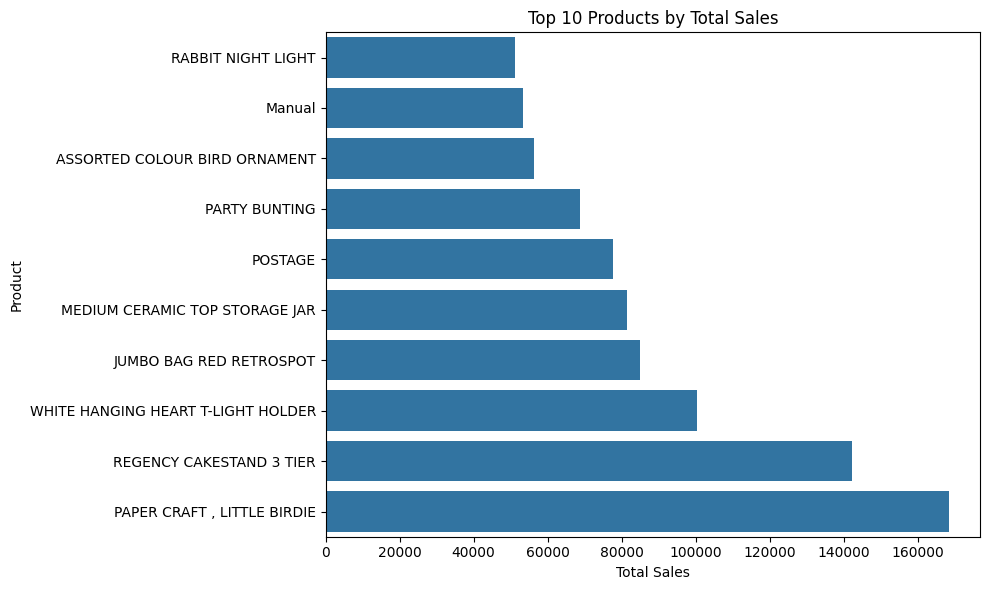

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate sales for each product
top_products = (
    df.groupby('Description')['Sales']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

# Create the chart
plt.figure(figsize=(10, 6))
sns.barplot(x=top_products.values, y=top_products.index)

plt.title('Top 10 Products by Total Sales')
plt.xlabel('Total Sales')
plt.ylabel('Product')
plt.tight_layout()
plt.show()


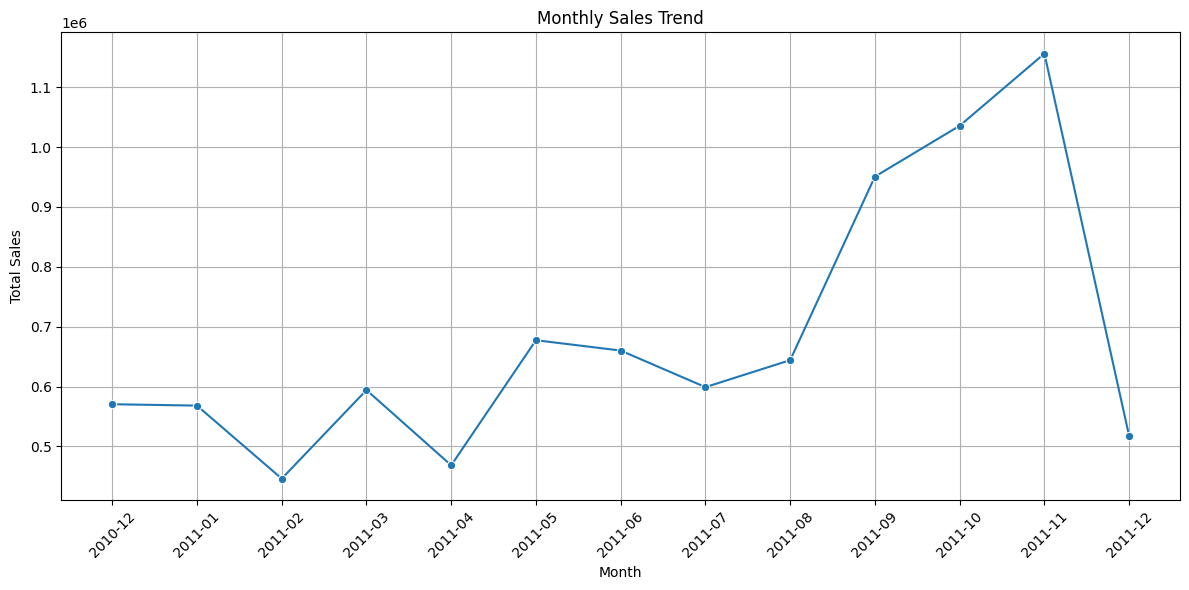

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Convert InvoiceDate to datetime
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Extract month and calculate sales
df['Month'] = df['InvoiceDate'].dt.to_period('M').astype(str)

monthly_sales = df.groupby('Month')['Sales'].sum().reset_index()

# Draw the chart
plt.figure(figsize=(12, 6))
sns.lineplot(data=monthly_sales, x='Month', y='Sales', marker='o')

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.savefig('monthly_sales_trend.png', dpi=300, bbox_inches='tight')
plt.show()


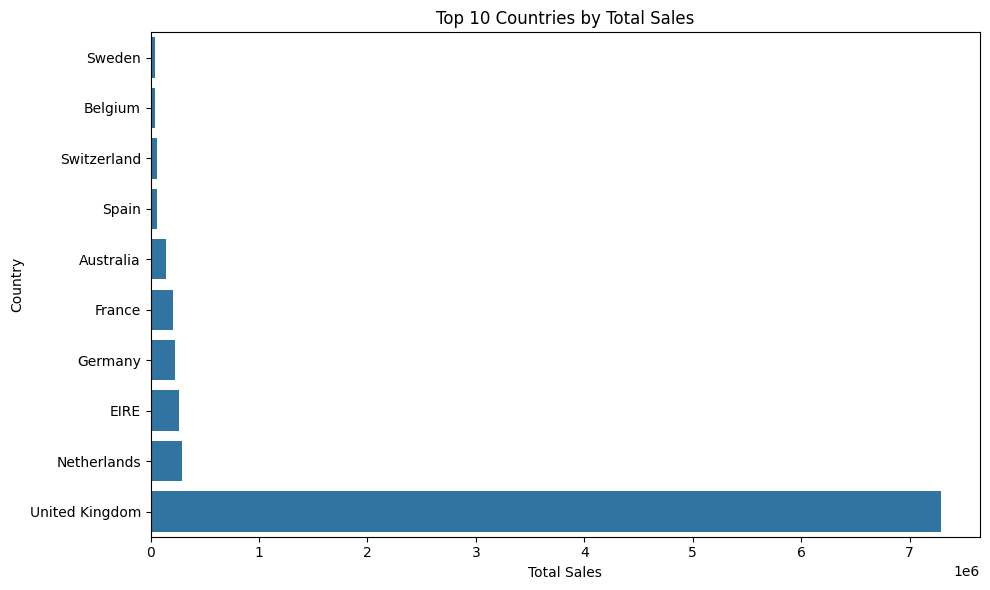

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate sales by country
country_sales = (
    df.groupby('Country')['Sales']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values()
)

# Create the chart
plt.figure(figsize=(10, 6))
sns.barplot(x=country_sales.values, y=country_sales.index)

plt.title('Top 10 Countries by Total Sales')
plt.xlabel('Total Sales')
plt.ylabel('Country')
plt.tight_layout()

# Save the chart
plt.savefig('sales_by_country.png', dpi=300, bbox_inches='tight')
plt.show()


In [ ]:
print("Dataset Information")
print("-------------------")

print("Number of rows and columns:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types and Missing Values:")
df.info()

Dataset Information
-------------------
Number of rows and columns: (392692, 9)

Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'Sales']

Data Types and Missing Values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 392692 entries, 0 to 392691
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    392692 non-null  int64  
 1   StockCode    392692 non-null  object 
 2   Description  392692 non-null  object 
 3   Quantity     392692 non-null  int64  
 4   InvoiceDate  392692 non-null  object 
 5   UnitPrice    392692 non-null  float64
 6   CustomerID   392692 non-null  int64  
 7   Country      392692 non-null  object 
 8   Sales        392692 non-null  float64
dtypes: float64(2), int64(3), object(4)
memory usage: 27.0+ MB


In [ ]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Sales
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [9]:

# Customer Purchase Behaviour Analysis

print("Total Sales:", round(df['Sales'].sum(), 2))

print("Total Customers:", df['CustomerID'].nunique())

# Top 10 countries by sales
country_sales = (
    df.groupby('Country')['Sales']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("\nTop 10 Countries by Sales:")
print(country_sales)

# Average sales per invoice
order_sales = df.groupby('InvoiceNo')['Sales'].sum()

print("\nAverage Order Value:", round(order_sales.mean(), 2))


Total Sales: 8887208.89
Total Customers: 4338

Top 10 Countries by Sales:
Country
United Kingdom    7285024.64
Netherlands        285446.34
EIRE               265262.46
Germany            228678.40
France             208934.31
Australia          138453.81
Spain               61558.56
Switzerland         56443.95
Belgium             41196.34
Sweden              38367.83
Name: Sales, dtype: float64

Average Order Value: 479.56


In [10]:

import pandas as pd

# Make sure invoice dates are in datetime format
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Use positive-quantity, positive-price purchase records
purchases = df[
    (df['Quantity'] > 0) &
    (df['UnitPrice'] > 0) &
    (df['CustomerID'].notna())
].copy()

# Set the reference date to one day after the latest transaction
reference_date = purchases['InvoiceDate'].max() + pd.Timedelta(days=1)

# Calculate RFM metrics for each customer
rfm = purchases.groupby('CustomerID').agg(
    Recency=('InvoiceDate',
             lambda dates: (reference_date - dates.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('Sales', 'sum')
).reset_index()

print("RFM analysis completed!")
print("Number of customers:", len(rfm))

rfm.head(10)


RFM analysis completed!
Number of customers: 4338


,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1797.24
3,12349,19,1,1757.55
4,12350,310,1,334.40
5,12352,36,8,2506.04
6,12353,204,1,89.00
7,12354,232,1,1079.40
8,12355,214,1,459.40
9,12356,23,3,2811.43


In [11]:

# Assign scores from 1 to 5 to each RFM metric

rfm['R_Score'] = pd.qcut(
    rfm['Recency'].rank(method='first'),
    5, labels=[5, 4, 3, 2, 1]
).astype(int)

rfm['F_Score'] = pd.qcut(
    rfm['Frequency'].rank(method='first'),
    5, labels=[1, 2, 3, 4, 5]
).astype(int)

rfm['M_Score'] = pd.qcut(
    rfm['Monetary'].rank(method='first'),
    5, labels=[1, 2, 3, 4, 5]
).astype(int)

# Combine the scores
rfm['RFM_Score'] = (
    rfm['R_Score'].astype(str) +
    rfm['F_Score'].astype(str) +
    rfm['M_Score'].astype(str)
)

print("RFM scores created successfully!")
rfm.head(10)


RFM scores created successfully!


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,12346,326,1,77183.60,1,1,5,115
1,12347,2,7,4310.00,5,5,5,555
2,12348,75,4,1797.24,2,4,4,244
3,12349,19,1,1757.55,4,1,4,414
4,12350,310,1,334.40,1,1,2,112
5,12352,36,8,2506.04,3,5,5,355
6,12353,204,1,89.00,1,1,1,111
7,12354,232,1,1079.40,1,1,4,114
8,12355,214,1,459.40,1,1,2,112
9,12356,23,3,2811.43,4,3,5,435


In [12]:

def segment_customer(row):
    if row['R_Score'] >= 4 and row['F_Score'] >= 4:
        return 'Loyal Active Customers'
    elif row['R_Score'] >= 4 and row['M_Score'] >= 4:
        return 'High Value Recent Customers'
    elif row['R_Score'] <= 2:
        return 'At Risk / Inactive Customers'
    elif row['F_Score'] <= 2 and row['R_Score'] >= 3:
        return 'New or Occasional Customers'
    else:
        return 'Regular Customers'

rfm['Segment'] = rfm.apply(segment_customer, axis=1)

print("Customer Segmentation Completed!")
print(rfm['Segment'].value_counts())

rfm.head(10)


Customer Segmentation Completed!
Segment
At Risk / Inactive Customers    1735
Loyal Active Customers          1121
Regular Customers                738
New or Occasional Customers      630
High Value Recent Customers      114
Name: count, dtype: int64


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
0,12346,326,1,77183.60,1,1,5,115,At Risk / Inactive Customers
1,12347,2,7,4310.00,5,5,5,555,Loyal Active Customers
2,12348,75,4,1797.24,2,4,4,244,At Risk / Inactive Customers
3,12349,19,1,1757.55,4,1,4,414,High Value Recent Customers
4,12350,310,1,334.40,1,1,2,112,At Risk / Inactive Customers
5,12352,36,8,2506.04,3,5,5,355,Regular Customers
6,12353,204,1,89.00,1,1,1,111,At Risk / Inactive Customers
7,12354,232,1,1079.40,1,1,4,114,At Risk / Inactive Customers
8,12355,214,1,459.40,1,1,2,112,At Risk / Inactive Customers
9,12356,23,3,2811.43,4,3,5,435,High Value Recent Customers


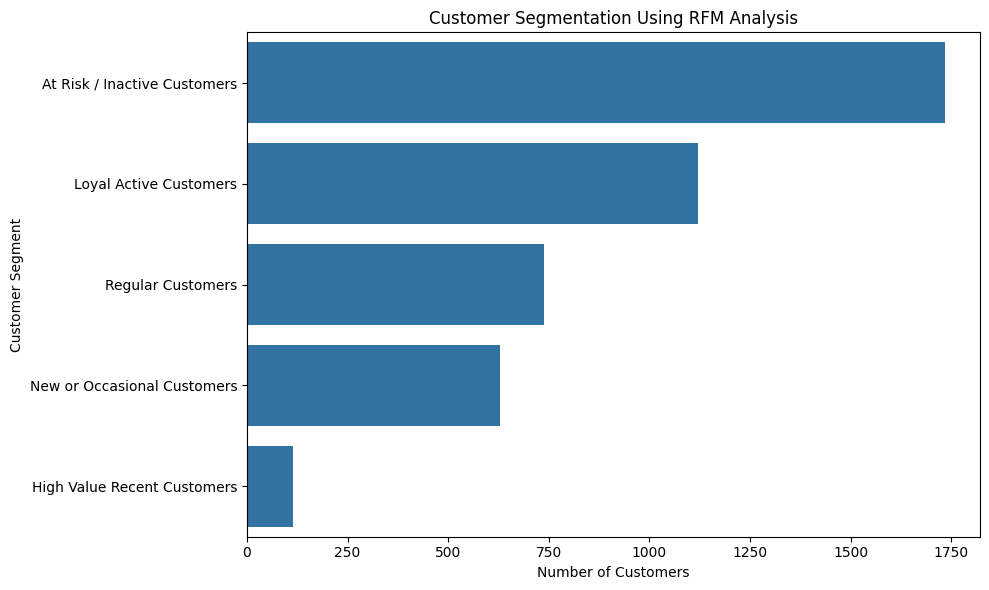

Segment
At Risk / Inactive Customers    1735
Loyal Active Customers          1121
Regular Customers                738
New or Occasional Customers      630
High Value Recent Customers      114
Name: count, dtype: int64


In [13]:

import matplotlib.pyplot as plt
import seaborn as sns

# Count customers in each segment
segment_counts = rfm['Segment'].value_counts()

# Create the chart
plt.figure(figsize=(10, 6))
sns.barplot(x=segment_counts.values, y=segment_counts.index)

plt.title('Customer Segmentation Using RFM Analysis')
plt.xlabel('Number of Customers')
plt.ylabel('Customer Segment')
plt.tight_layout()

# Save the chart
plt.savefig('customer_segmentation.png',
            dpi=300, bbox_inches='tight')
plt.show()

print(segment_counts)


In [15]:

from google.colab import files
files.download('customer_segmentation.png')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

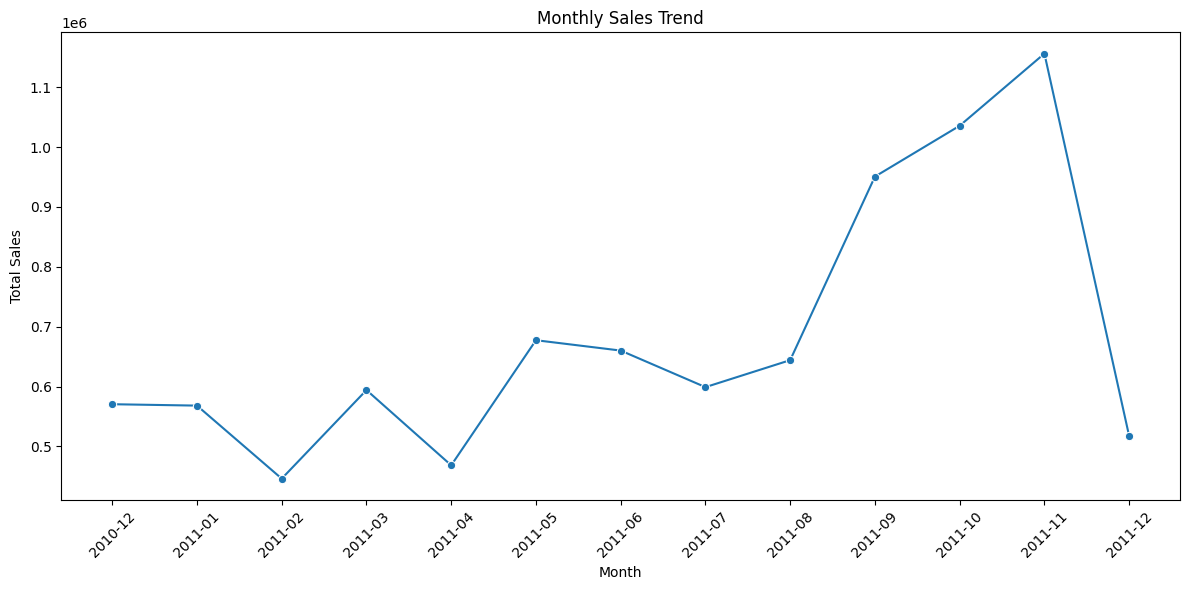

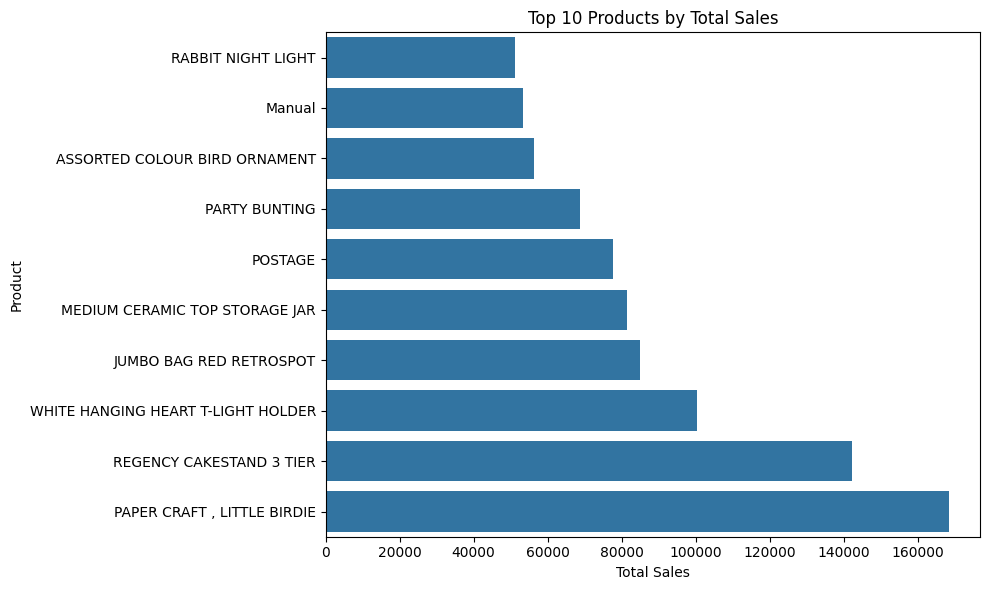

Both charts saved successfully!


In [16]:

# Save both charts again

import matplotlib.pyplot as plt
import seaborn as sns

# Monthly sales chart
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['Month'] = df['InvoiceDate'].dt.to_period('M').astype(str)
monthly_sales = df.groupby('Month')['Sales'].sum().reset_index()

plt.figure(figsize=(12, 6))
sns.lineplot(data=monthly_sales, x='Month', y='Sales', marker='o')
plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('monthly_sales_trend.png', dpi=300, bbox_inches='tight')
plt.show()

# Top 10 products chart
top_products = (
    df.groupby('Description')['Sales']
    .sum()
    .nlargest(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_products.values, y=top_products.index)
plt.title('Top 10 Products by Total Sales')
plt.xlabel('Total Sales')
plt.ylabel('Product')
plt.tight_layout()
plt.savefig('top_10_products.png', dpi=300, bbox_inches='tight')
plt.show()

print("Both charts saved successfully!")


In [17]:

from google.colab import files

files.download('monthly_sales_trend.png')
files.download('top_10_products.png')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:

# Export customer segmentation results to Excel

rfm.to_excel('Customer_Segmentation_Results.xlsx', index=False)

print("Customer segmentation results exported successfully!")


Customer segmentation results exported successfully!


In [19]:

from google.colab import files

files.download('Customer_Segmentation_Results.xlsx')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>